# 03. 승패 예측 모델

안녕하세요! **KBO 승패 예측 프로젝트의 세 번째 이야기**예요.
02번 노트북에서 경기마다 피처 26개를 만들었으니, 이번에는 그 숫자들로 **"오늘 홈팀이 이길 확률"을 계산하는 모델**을 만들고, 학습과 고르기에 쓰지 않고 떼어 둔 **2026 시즌**으로 성적을 매겨요.

### 이 노트북이 하는 일
- 12개 시즌을 **학습(2015~2024) / 검증(2025) / 시험(2026)** 세 구간으로 나누고, 구간마다 무엇에 쓰는지 정해요.
- 모델 없이 찍는 **단순 규칙 3가지**(베이스라인)의 성적을 먼저 재요. 모델은 이걸 넘어야 의미가 있어요.
- 두 가지 모델, **로지스틱 회귀**와 **LightGBM**을 학습하고 속을 들여다봐요(계수 표, early stopping 곡선).
- 모델이 말하는 확률이 "말한 만큼 맞는지" **캘리브레이션**으로 다듬고, 신뢰도 곡선으로 확인해요.
- **2026 성적표**: 정확도·log loss·Brier 점수를 보고, 베이스라인보다 나은 게 우연이 아닌지 **McNemar 검정**으로 따져요. 잘한 점과 아직 부족한 점을 그대로 적어요.
- 어떤 피처가 중요했는지, 그리고 한 경기의 예측 확률이 어떤 요인들로 이루어졌는지(**요인 분해**) 그림으로 봐요.
- 매일 사이트에 예측을 올리는 **라이브 모델**을 학습하고, 마지막으로 이 노트북의 결과가 저장소의 `data/public/model_report.json`과 **완전히 같은지** 확인해요.

### 왜 필요한가요?
피처 26개는 재료일 뿐이에요. 이 숫자들을 **확률 하나**("홈팀 승리 61%")로 바꿔 주는 게 모델이에요.
그런데 야구는 운이 많이 섞인 종목이라(02번에서 본 것처럼 가장 유리한 경기 묶음도 홈팀 승률이 60% 안팎이에요), 정확도 몇 %p 차이가 **실력인지 운인지** 가려내기가 어려워요.
그래서 이 노트북은 "모델을 잘 만드는 것"만큼 **"성적을 정직하게 매기는 것"**에 공을 들여요. 고르기는 2025로만 하고, 2026은 어떤 학습·선택에도 쓰지 않고 채점에만 써요(개발 중에 있었던 일은 2번에 그대로 적어 뒀어요).

### 왜 모델이 두 벌인가요?
| 모델 | 파일 | 배운 시즌 | 쓰임 |
|---|---|---|---|
| **성적표용** `report-2026` | `models/report-2026.pkl` | 2015~2024 (2025는 고르기에만) | 2026 시즌 성적을 정직하게 매기는 데만 써요. 한 번 만든 뒤 **얼려 둬요** |
| **라이브용** `v0.2` | `models/win_model.pkl` | 2015~2026 전부 | 매일 사이트에 올라가는 예측을 만들어요 |

시험 문제를 미리 본 학생의 점수는 믿을 수 없죠. 라이브 모델은 2026 경기까지 배웠기 때문에, 2026으로 채점하면 점수가 부풀어요.
그래서 2026을 **전혀 보지 않은** 성적표용 모델을 따로 만들어 그 점수를 공개해요. 이렇게 학습과 고르기에 쓰지 않고 마지막 채점용으로만 떼어 둔 데이터를 **홀드아웃**(holdout)이라고 해요.
라이브 모델은 성적표 모델과 **똑같은 방법**(알고리즘·캘리브레이션·트리 수)으로 데이터만 더 많이 배운 모델이라, 실력은 성적표 수준이라고 기대할 수 있어요.

### 짝이 되는 `.py` 파일
이 노트북도 계산을 새로 짜지 않고 `src/kbo_predict/`의 함수를 **불러서 쓰기만** 해요. 그래서 노트북 결과와 GitHub Actions가 만드는 결과가 언제나 같아요(11번에서 직접 확인해요).

| 파일 | 하는 일 |
|---|---|
| `train_win.py` | 모델 학습(`fit_model`)·예측(`predict_proba`)·요인 분해(`explain`), 평가(`evaluate`, `baselines`, `feature_importance`), 그리고 전체 절차 `train_report`(성적표용)·`train_live`(라이브용). 명령줄에서는 `python -m kbo_predict.train_win report` / `live` |
| `features.py` | 02번에서 저장한 피처 파일 읽기(`load_features`), 피처 이름과 한글 이름(`FEATURE_NAMES`, `FACTOR_LABELS`) |
| `predict.py` | 사이트에 보여 주는 "요인 pp"를 계산해요(`factor_pp`) |

### 읽는 순서
1. 준비
2. 시즌 나누기 — 학습 / 검증 / 시험
3. 베이스라인 3종
4. 로지스틱 회귀
5. LightGBM
6. 캘리브레이션 (공식 절차 `train_report` 실행)
7. 2026 성적표
8. 피처 중요도와 한 경기 요인 분해
9. 라이브 모델
10. 유형 상성 피처를 넣으면?
11. 동일성 확인
12. 요약과 다음 이야기

> 결과만 궁금하시면 **7번(성적표)**만 보셔도 충분해요.
> 02번 노트북을 먼저 실행해서 `data/processed/features.parquet`가 있어야 해요. 인터넷 없이 실행되고, 보통 10초 안팎이면 끝나요(실행 시간은 11번 셀 맨 아래에 나와요).

## 1. 준비

02번 노트북과 같은 준비 셀이에요.

- 이 노트북은 `notebooks/` 폴더에서 실행되니까, 한 단계 위(`Path.cwd().parent`)가 프로젝트 루트예요.
- `src/`를 파이썬 경로에 넣어서 `kbo_predict` 패키지를 불러올 수 있게 해요.
- 그래프의 한글이 깨지지 않도록 한글 폰트를 지정하고, 그래프 색과 격자 모양을 02번과 같게 맞춰요.
- 02번에서 저장한 피처 파일을 읽고, 그 파일의 **SHA256**(파일 내용으로 만든 64자리 지문)이 공개된 성적표(`model_report.json`)에 적힌 지문과 같은지 확인해요. 같아야 "성적표를 만든 데이터 = 지금 읽은 데이터"예요.

**출력 보는 법:** 경기 수(8,465)와 시즌 범위, 그리고 지문 비교 결과 `True`가 보이면 준비 끝이에요.

In [1]:
import json
import logging
import os
import sys
import tempfile
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

T0 = time.time()                                           # 노트북 전체 실행 시간을 재기 시작
ROOT = Path.cwd().parent                                   # notebooks/의 한 단계 위 = 프로젝트 루트
sys.path.insert(0, str(ROOT / "src"))                      # kbo_predict 패키지를 불러오기 위해
os.environ.setdefault("KBO_DATA_DIR", str(ROOT / "data"))  # raw_store가 데이터를 찾는 폴더

# 그래프 한글 폰트: 윈도우 → 맥 → 리눅스(나눔) → 기본 폰트 순으로 있는 것을 써요
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False                 # 마이너스 기호가 네모로 깨지지 않게
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 없는 후보 폰트 안내 메시지는 숨겨요
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e4e0", "axes.axisbelow": True})
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#e07b39", "#b8b6b0", "#52514e"  # 주 색, 대비 색, 보조 색, 글자·보조선 색
pd.set_option("display.width", 120)
pd.set_option("display.max_rows", 40)

from kbo_predict import cluster, features, predict
from kbo_predict import train_win as tw

FEATURES_PATH = ROOT / "data" / "processed" / "features.parquet"   # 02번 노트북이 저장한 파일
df = features.load_features(FEATURES_PATH)
committed = json.loads((ROOT / "data" / "public" / "model_report.json").read_text(encoding="utf-8"))  # 저장소의 성적표
features_sha = features.features_sha256(FEATURES_PATH)

print(f"피처 파일: {len(df):,}경기 · 시즌 {df['season'].min()}~{df['season'].max()} · 피처 {len(features.FEATURE_NAMES)}개")
print("피처 파일 SHA256이 model_report.json의 features_sha256과 같나요?:", features_sha == committed["features_sha256"])
assert features_sha == committed["features_sha256"]

피처 파일: 8,465경기 · 시즌 2015~2026 · 피처 26개
피처 파일 SHA256이 model_report.json의 features_sha256과 같나요?: True


## 2. 시즌 나누기 — 학습 / 검증 / 시험

12개 시즌을 **시간 순서대로** 세 구간으로 나눠요.

| 구간 | 시즌 | 무엇에 쓰나 |
|---|---|---|
| **학습**(train) | 2015~2024 | 모델이 계수·나무를 배워요. 6번의 캘리브레이터도 이 구간으로 맞춰요 |
| **검증**(validation, val) | 2025 | **고르기**에만 써요: LightGBM 나무 개수(early stopping), 캘리브레이션 방법, 두 알고리즘 중 무엇을 쓸지, 유의성 검정의 비교 대상 |
| **시험**(test) | 2026 | 어떤 학습·선택에도 쓰지 않고 **채점에만** 써요 — 홀드아웃 |

### 왜 무작위로 섞지 않고 시간으로 자르나요?
실제 예측은 언제나 "과거로 배워 미래를 맞히는" 일이에요. 경기를 무작위로 섞어서 나누면 2026년 경기로 배워 2020년 경기를 맞히는 셈이 되고, 같은 시즌의 분위기(리그 타고투저 등)를 미리 엿보게 돼요. 평가도 실제와 같은 모양이어야 믿을 수 있어요.

### 왜 검증 구간이 따로 필요한가요?
"나무를 몇 그루 심을까?", "캘리브레이션은 어떤 방법으로?" 같은 선택을 시험 구간(2026)의 점수를 보며 하면, 2026에 우연히 잘 맞는 쪽을 고르게 돼요. 그러면 2026 점수가 더 이상 공정한 시험이 아니에요.
그래서 모든 선택은 2025에서 하고, 2026은 채점에만 써요.

> **솔직한 고백:** 2026 시즌은 어떤 학습·선택에도 쓰지 않았어요. 다만 개발하는 동안 2026 지표를 확인했고, 그 뒤 캘리브레이션 선택 절차를 **한 번 바꿨어요**(R7). 예전 절차는 2025 검증 구간으로 캘리브레이터를 맞추고 같은 2025로 방법을 골랐는데, 이렇게 하면 유연한 isotonic을 편애하는 표본 내 편향이 생겨요(6번에서 자세히 봐요). 예전 절차의 결과는 **LightGBM + isotonic, 2026 정확도 .588 / log loss .679**(선발 ERA 규칙 대비 McNemar p = .321)였고, 바꾼 뒤의 결과가 7번의 성적표예요. 바꾼 이유는 위의 편향이었지만, 2026 점수를 본 뒤에 바꾼 것은 사실이라 "한 번도 보지 않은 시험"이라고는 말하지 않을게요.

**출력 보는 법:** 표는 구간별 경기 수와 홈팀 승률이에요. 그림은 시즌마다 학습 행(경기) 수를 구간 색으로 칠한 거예요.

,시즌,경기 수,홈팀 승률,쓰임
학습(train),2015~2024,7065,52.9%,모델 학습 + 캘리브레이터 맞추기
검증(val),2025,698,51.3%,고르기(나무 수·캘리브레이션·알고리즘·비교 대상)
시험(test),2026,702,51.4%,마지막에 한 번 채점


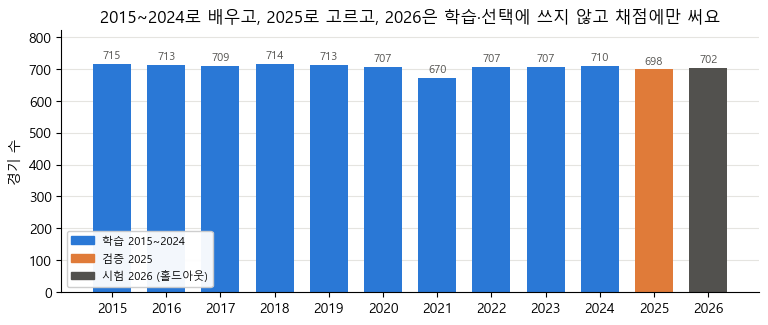

In [2]:
TRAIN_SEASONS, VAL_SEASON, TEST_SEASON = list(range(2015, 2025)), 2025, 2026   # train_report의 기본값과 같아요
train = df[df["season"].isin(TRAIN_SEASONS)]
val = df[df["season"] == VAL_SEASON]
test = df[df["season"] == TEST_SEASON]

split = pd.DataFrame({
    "시즌": [f"{TRAIN_SEASONS[0]}~{TRAIN_SEASONS[-1]}", str(VAL_SEASON), str(TEST_SEASON)],
    "경기 수": [len(train), len(val), len(test)],
    "홈팀 승률": [f"{part['y'].mean():.1%}" for part in (train, val, test)],
    "쓰임": ["모델 학습 + 캘리브레이터 맞추기", "고르기(나무 수·캘리브레이션·알고리즘·비교 대상)", "마지막에 한 번 채점"],
}, index=["학습(train)", "검증(val)", "시험(test)"])
display(split)

per_season = df.groupby("season").size()
role_color = {s: (BLUE if s in TRAIN_SEASONS else ORANGE if s == VAL_SEASON else INK) for s in per_season.index}
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(per_season.index.astype(str), per_season.values, color=[role_color[s] for s in per_season.index], width=0.7)
ax.bar_label(bars, fontsize=8, color=INK, padding=2)
ax.legend(handles=[Patch(color=BLUE, label="학습 2015~2024"), Patch(color=ORANGE, label="검증 2025"),
                   Patch(color=INK, label="시험 2026 (홀드아웃)")], loc="lower left", fontsize=8, framealpha=0.95)
ax.set(title="2015~2024로 배우고, 2025로 고르고, 2026은 학습·선택에 쓰지 않고 채점에만 써요", ylabel="경기 수", ylim=(0, 820))
plt.show()

**해석:** 학습 7,065경기, 검증 698경기, 시험 702경기예요. 시험 구간은 전체의 8% 정도라 작아 보이지만, 한 시즌 전체(정규시즌 전 경기)라서 "다음 시즌을 통째로 예측하면 어떨까?"라는 실제 상황과 똑같아요.
홈팀 승률이 학습 52.9% → 검증 51.3% → 시험 51.4%로 최근 두 시즌에 조금 낮아요. "무조건 홈팀"이라고 찍는 방법은 최근 시즌일수록 덜 통한다는 뜻이에요.

## 3. 베이스라인 3종 — 모델이 넘어야 할 기준선

모델이 쓸모 있는지 알려면 **비교 대상**이 있어야 해요. 머신러닝 없이 누구나 할 수 있는 단순한 찍기 규칙 3가지를 **베이스라인**(baseline, 기준선)으로 정했어요.

| 규칙 | 이렇게 찍어요 | 쓰는 피처 |
|---|---|---|
| 무조건 홈팀 | 모든 경기에서 홈팀 승 | 없음 |
| 승률 높은 팀 | 올 시즌(전날까지) 승률이 높은 팀 승 | `win_pct_diff` |
| 선발 ERA 낮은 팀 | 선발투수의 평균자책점(당해+직전 시즌)이 낮은 팀 승 | `starter_era_diff` |

값이 같거나 비어 있으면(개막전, 기록 없는 선발) 홈팀으로 찍어요. 계산은 `tw.baselines(구간)` 한 줄이에요.

**출력 보는 법:** 숫자는 정확도(%)예요. 702경기 중 몇 %를 맞혔는지예요.

In [3]:
BASELINE_NAMES = {"home_always": "무조건 홈팀", "better_win_pct": "승률 높은 팀", "lower_starter_era": "선발 ERA 낮은 팀"}
base_val, base_test = tw.baselines(val), tw.baselines(test)
base_tbl = pd.DataFrame({"2025 검증 정확도(%)": base_val, "2026 시험 정확도(%)": base_test}).rename(index=BASELINE_NAMES)
display((base_tbl * 100).round(1))
best_val_rule = max(base_val, key=base_val.get)
print(f"2025(검증)에서 가장 잘한 규칙: {BASELINE_NAMES[best_val_rule]} ({base_val[best_val_rule]:.1%})")

,2025 검증 정확도(%),2026 시험 정확도(%)
무조건 홈팀,51.3,51.4
승률 높은 팀,54.7,55.4
선발 ERA 낮은 팀,55.3,56.7


2025(검증)에서 가장 잘한 규칙: 선발 ERA 낮은 팀 (55.3%)


**해석:**
- **무조건 홈팀**은 51~52%로 동전 던지기와 거의 같아요. 최근 KBO는 홈 어드밴티지가 작아요.
- **승률 높은 팀**은 54~55%, **선발 ERA 낮은 팀**은 55~57%예요. 단 하나의 숫자만 보고도 홈팀 찍기보다 3.4~5.3%p 나아요(**%p**는 퍼센트포인트: 퍼센트끼리의 차이예요. 51.3% → 54.7%는 3.4%p 오른 거예요). 특히 "오늘 선발이 누구냐"가 시즌 성적만큼 강한 신호라는 02번의 결론과 같아요.
- 2025에서 가장 잘한 규칙은 **선발 ERA 낮은 팀**이에요. 7번에서 유의성 검정을 할 때, 이 규칙을 **미리(2025에서) 정한 비교 대상**으로 써요. 2026 점수를 보고 비교 대상을 고르면 그것도 시험지를 미리 본 셈이 되거든요.

## 4. 로지스틱 회귀 — 피처마다 "얼마나, 어느 쪽으로"

### 로지스틱 회귀란?
**로지스틱 회귀**(logistic regression)는 확률을 예측하는 가장 기본적인 모델이에요.
피처마다 **가중치(계수)**를 하나씩 정해서 "점수 = 절편 + 계수₁×피처₁ + 계수₂×피처₂ + …"를 더한 다음, 이 점수를 0~1 사이 확률로 바꿔요(시그모이드 함수, 점수 0 → 50%, 점수가 클수록 100%에 가까워져요). 이 점수를 **로짓**(logit, log-odds)이라고 불러요.
장점은 **설명하기 쉽다**는 거예요. 계수가 양수면 "그 피처가 클수록 홈팀이 유리", 음수면 "원정팀이 유리"예요.

우리 모델은 계산 전에 두 가지를 해요(`train_win.py`의 `Pipeline`).
1. 빈 값(NaN)은 **학습 구간의 중앙값**으로 채워요.
2. 피처마다 **표준화**해요(평균 0, 표준편차 1로 맞추기). 승률 차이(±0.3)와 이닝 차이(±100)처럼 단위가 다른 피처의 계수를 나란히 비교하려고요. 그래서 계수는 "그 피처가 **표준편차 1만큼** 홈 쪽으로 클 때 로짓이 얼마나 변하나"예요.

### 성적을 재는 세 가지 자
| 지표 | 뜻 | 좋은 방향 | 기준값(모든 경기에 50%라고 말할 때) |
|---|---|---|---|
| **정확도**(accuracy) | 확률이 50% 이상인 쪽을 승자로 찍었을 때 맞힌 비율 | 높을수록 | 홈팀 승률과 같음 |
| **log loss**(로그 손실) | 실제 결과에 준 확률의 −log 평균. 진 팀에 90%를 주면 크게 벌점, 60%를 주면 작게 벌점 | **낮을수록** | 0.6931 |
| **Brier 점수** | (예측 확률 − 실제 결과(1 또는 0))²의 평균 | **낮을수록** | 0.2500 |

정확도는 "누가 이기나"만 보고, log loss와 Brier는 "**확률을 얼마나 잘 말했나**"까지 봐요. 사이트는 확률(61% 등)을 보여 주니까, 모델을 고를 때는 정확도보다 **log loss**를 기준으로 써요.

**출력 보는 법:** 표는 2015~2024로 학습한 로지스틱 회귀의 표준화 계수를 **절댓값이 큰 순서**로 26개 모두 보여 줘요. 아래 줄은 2025(검증) 성적이에요(캘리브레이션 전).

In [4]:
lr_raw = tw.fit_model(train, kind="lr", version="notebook", seasons=TRAIN_SEASONS)   # 캘리브레이션 전 로지스틱 회귀
clf = lr_raw["model"].named_steps["clf"]                                             # Pipeline의 마지막 단계(LogisticRegression)

coef_tbl = pd.DataFrame({"피처": features.FEATURE_NAMES,
                         "한글 이름": [features.FACTOR_LABELS[n] for n in features.FEATURE_NAMES],
                         "표준화 계수": clf.coef_[0]})
coef_tbl["방향"] = np.where(coef_tbl["표준화 계수"] > 0, "클수록 홈 유리", "클수록 원정 유리")
coef_tbl = coef_tbl.loc[coef_tbl["표준화 계수"].abs().sort_values(ascending=False).index]
coef_tbl.index = range(1, len(coef_tbl) + 1)
display(coef_tbl.round(3))

intercept = clf.intercept_[0]
print(f"절편 {intercept:+.3f} → 모든 피처가 학습 평균인 경기의 홈팀 승리 확률 {1 / (1 + np.exp(-intercept)):.1%}")
lr_val = tw.evaluate(lr_raw, val)
print(f"2025 검증: 정확도 {lr_val['accuracy']:.1%} · log loss {lr_val['log_loss']:.4f} · Brier {lr_val['brier']:.4f}"
      f"   (기준: 50%만 말하면 log loss {np.log(2):.4f} · Brier 0.2500)")

,피처,한글 이름,표준화 계수,방향
1,pyth_diff,피타고리안 기대 승률 차이,0.151,클수록 홈 유리
2,run_diff_diff,경기당 득실차,-0.134,클수록 원정 유리
3,starter_k9_diff,선발 9이닝당 삼진 차이,0.121,클수록 홈 유리
4,starter_fip_diff,선발 FIP 차이,-0.119,클수록 원정 유리
5,win_pct_diff,팀 승률 차이,0.116,클수록 홈 유리
6,prev_season_diff,지난 시즌 승률 차이,0.105,클수록 홈 유리
7,starter_ip_diff,선발 누적 이닝 차이,0.088,클수록 홈 유리
8,starter_bb9_diff,선발 9이닝당 볼넷 차이,-0.082,클수록 원정 유리
9,hr_rate_diff,타선 홈런 비율 차이,0.080,클수록 홈 유리
10,k_rate_diff,타선 삼진 비율 차이,-0.078,클수록 원정 유리


절편 +0.119 → 모든 피처가 학습 평균인 경기의 홈팀 승리 확률 53.0%
2025 검증: 정확도 58.0% · log loss 0.6772 · Brier 0.2421   (기준: 50%만 말하면 log loss 0.6931 · Brier 0.2500)


**해석 (계수가 큰 순서로 한 줄씩):**
1. `pyth_diff`(+0.151) — 득실점으로 본 "있어야 할 승률"이 홈팀이 높을수록 홈팀이 유리해요. 가장 큰 계수예요.
2. `run_diff_diff`(−0.134) — 경기당 득실차는 **음수**예요. "득실차가 좋을수록 불리하다"는 뜻이 아니라, 피타고리안 승률과 거의 같은 정보라서 둘이 나눠 가지다 보니 생긴 현상이에요(아래 상자 참고).
3. `starter_k9_diff`(+0.121) — 홈 선발이 삼진을 더 많이 잡는 투수일수록 홈팀이 유리해요.
4. `starter_fip_diff`(−0.119) — 홈 선발의 FIP가 높을수록(= 더 나쁜 투수일수록) 홈팀이 불리해요. 방향이 상식과 같아요.
5. `win_pct_diff`(+0.116) — 올 시즌 승률이 높은 팀이 유리해요.
6. `prev_season_diff`(+0.105) — 지난 시즌 승률도 여전히 도움이 돼요(특히 시즌 초).
7. `starter_ip_diff`(+0.088) — 많이 던져 온 선발(= 팀이 믿고 맡기는 투수)이 유리해요.
8. `starter_bb9_diff`(−0.082) — 볼넷이 많은 선발은 불리해요.
9. `hr_rate_diff`(+0.080), `k_rate_diff`(−0.078) — 홈런을 많이 치고 삼진을 덜 당하는 타선이 유리해요.

11위(`rest_diff`, +0.050)부터는 계수가 0.05 이하라서 영향이 작아요. 특히 `starter_era_diff`(−0.006)가 거의 0인 건, 같은 선발의 실력을 FIP·K/9·BB/9가 더 잘 설명해서 ERA에는 몫이 거의 남지 않았기 때문이에요.

> **비슷한 피처끼리는 계수를 나눠 가져요 (다중공선성).** 승률·피타고리안 승률·득실차는 거의 같은 이야기를 해요. 이렇게 서로 강하게 얽힌 피처가 함께 들어가면(다중공선성), 모델은 그 합만 맞으면 되기 때문에 하나는 크게 양수, 하나는 음수로 나눌 수 있어요. 그래서 **계수 하나하나보다는 묶음 전체의 방향**(팀 성적이 좋으면 유리)을 읽는 게 안전해요. 예측 확률 자체에는 문제가 없어요.

**성적:** 2025 검증 정확도 58.0%, log loss 0.6772예요. 50%만 말하는 기준(0.6931)보다 낮으니 확률에 정보가 담겨 있다는 뜻이에요. 아주 작은 차이처럼 보이지만, 운이 큰 승패 예측에서는 이 노트북의 모든 모델이 0.67~0.69 사이에 있어요. 그 좁은 폭 안에서의 차이가 실력 차이예요.

## 5. LightGBM — 나무를 몇 그루 심을까? (early stopping)

### LightGBM이란?
**LightGBM**은 작은 **결정 나무**(decision tree: "선발 FIP 차이 < −1인가? → 예/아니요"처럼 질문을 이어 가며 경기를 나누는 모델) 여러 그루를 **차례로** 쌓는 모델이에요(그래디언트 부스팅).
새 나무는 앞의 나무들이 틀린 만큼을 보완하도록 배워요. 로지스틱 회귀와 달리 "선발 차이가 클 때만 승률 차이가 중요하다" 같은 **조합 효과**나 꺾인 관계도 잡을 수 있어요. 빈 값(NaN)도 스스로 처리해요.

### early stopping
나무를 너무 많이 쌓으면 학습 데이터의 **우연한 무늬까지 외워 버려요**(과적합). 그러면 학습 성적은 계속 좋아지는데, 처음 보는 경기 성적은 오히려 나빠져요.
**early stopping**(조기 종료)은 나무를 한 그루씩 늘리며 **검증 구간(2025)의 log loss**를 지켜보다가, 가장 좋았던 지점의 나무 수를 쓰는 방법이에요. 공식 절차(`train_win.py`)는 50그루 연속 나아지지 않으면 멈춰요.

이 그림을 그리려고, 이 셀만 **LightGBM 라이브러리를 직접** 불러요. 공식 절차와 같은 설정(`tw.LGBM_PARAMS`)으로 나무 300그루를 끝까지 심으면서, 한 그루마다 학습·검증 log loss를 기록하게 하는 거예요(`evals_result_`). 프로젝트 로직을 새로 짠 게 아니라, 라이브러리가 기록해 둔 곡선을 꺼내 보기만 해요.

**출력 보는 법:** 파란 선이 2025 검증 log loss, 회색 선이 학습 log loss예요. 세로 점선이 검증 log loss가 가장 낮은 지점이에요.

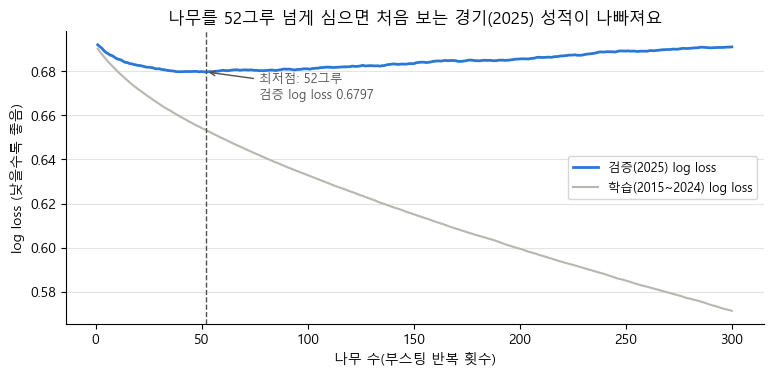

검증 log loss: 1그루 0.6920 → 52그루 0.6797 → 300그루 0.6911
학습 log loss: 1그루 0.6902 → 52그루 0.6533 → 300그루 0.5713


In [5]:
X_train, X_val = train[features.FEATURE_NAMES].astype(float), val[features.FEATURE_NAMES].astype(float)
curve_model = lgb.LGBMClassifier(**tw.LGBM_PARAMS, n_estimators=300)   # 공식 설정 그대로, 멈추지 않고 300그루
curve_model.fit(X_train, train["y"], eval_X=(X_train, X_val), eval_y=(train["y"], val["y"]),
                eval_names=["train", "val"], eval_metric="binary_logloss")
train_curve = np.array(curve_model.evals_result_["train"]["binary_logloss"])
val_curve = np.array(curve_model.evals_result_["val"]["binary_logloss"])
best_round = int(np.argmin(val_curve)) + 1                              # 나무 수는 1부터 세요

rounds = np.arange(1, len(val_curve) + 1)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(rounds, val_curve, color=BLUE, linewidth=2, label="검증(2025) log loss")
ax.plot(rounds, train_curve, color=GRAY, linewidth=1.5, label="학습(2015~2024) log loss")
ax.axvline(best_round, color=INK, linestyle="--", linewidth=1)
ax.annotate(f"최저점: {best_round}그루\n검증 log loss {val_curve[best_round - 1]:.4f}", xy=(best_round, val_curve[best_round - 1]),
            xytext=(best_round + 25, val_curve[best_round - 1] - 0.012), fontsize=9, color=INK,
            arrowprops={"arrowstyle": "->", "color": INK})
ax.set(title=f"나무를 {best_round}그루 넘게 심으면 처음 보는 경기(2025) 성적이 나빠져요",
       xlabel="나무 수(부스팅 반복 횟수)", ylabel="log loss (낮을수록 좋음)")
ax.legend(fontsize=9)
plt.show()
print(f"검증 log loss: 1그루 {val_curve[0]:.4f} → {best_round}그루 {val_curve[best_round - 1]:.4f} → 300그루 {val_curve[-1]:.4f}")
print(f"학습 log loss: 1그루 {train_curve[0]:.4f} → {best_round}그루 {train_curve[best_round - 1]:.4f} → 300그루 {train_curve[-1]:.4f}")

**해석:** 학습 log loss(회색)는 나무를 심을수록 끝없이 내려가지만, 검증 log loss(파란색)는 **52그루**에서 바닥을 찍고 다시 올라가요. 52그루 이후의 나무들은 2015~2024의 우연한 무늬를 외우는 데 쓰였다는 뜻이에요.
300그루까지 가면 검증 log loss가 50%만 말하는 기준(0.6931)에 가까워질 만큼 나빠져요. 그래서 공식 모델은 52그루를 써요(6번에서 `train_report`가 고른 값과 같은지 확인해요).

> **솔직한 한 줄:** LightGBM에서는 2025 검증 구간이 두 가지 일을 해요. 나무 수(early stopping)를 정하는 데 한 번, 6번에서 두 알고리즘 중 하나를 고르는 데 또 한 번. 같은 데이터로 두 번 고르면 LightGBM의 검증 점수가 살짝 좋게 나올 수 있어요. 다만 이 치우침은 LightGBM 쪽에 유리한 방향인데도 2025 log loss 비교에서는 로지스틱 회귀가 이겼으니(6번), 실제 선택은 바뀌지 않았어요. 그리고 2026 시험 구간은 어느 쪽에도 쓰지 않았으니, 7번의 성적표는 공정해요.

### 52그루 LightGBM vs 로지스틱 회귀 (2025, 캘리브레이션 전)
이제 `tw.fit_model`로 공식 절차와 똑같이 52그루 LightGBM을 학습해서, 4번의 로지스틱 회귀와 2025 성적을 나란히 놓아 볼게요.

**출력 보는 법:** 정확도는 높을수록, log loss·Brier는 낮을수록 좋아요.

In [6]:
lgbm_raw = tw.fit_model(train, kind="lgbm", n_estimators=best_round, version="notebook", seasons=TRAIN_SEASONS)
KIND_NAMES = {"lr": "로지스틱 회귀", "lgbm": "LightGBM"}
raw_cmp = pd.DataFrame({KIND_NAMES["lr"]: tw.evaluate(lr_raw, val), KIND_NAMES["lgbm"]: tw.evaluate(lgbm_raw, val)}).T
raw_cmp["n"] = raw_cmp["n"].astype(int)
display(raw_cmp.round(4))

,n,accuracy,log_loss,brier
로지스틱 회귀,698,0.5802,0.6772,0.2421
LightGBM,698,0.5731,0.6797,0.2433


**해석:** 로지스틱 회귀가 정확도(58.0% vs 57.3%)와 log loss(0.6772 vs 0.6797) 모두 조금 나아요.
더 복잡한 LightGBM이 단순한 로지스틱 회귀를 못 이기는 건 승패 예측에서 흔한 일이에요. 피처 대부분이 "차이가 클수록 유리"한 **곧은 관계**라서 선형 모델로 충분하고, 경기 결과에 운이 많이 섞여 있어서 복잡한 모델이 잡아낼 무늬가 많지 않아요.

## 6. 캘리브레이션 — "60%라고 말한 경기는 정말 60% 이겼나?"

### 캘리브레이션이란?
모델이 "홈팀 승리 60%"라고 말한 경기들을 모아 보면, 실제로 홈팀이 **60% 정도** 이겨야 해요. 이렇게 **말한 확률과 실제 빈도가 맞는 것**을 **캘리브레이션**(calibration, 보정)이 잘 됐다고 해요.
사이트는 확률을 그대로 보여 주니까, 정확도만큼 중요해요. 모델의 확률을 한 번 더 고쳐 주는 작은 모델을 **캘리브레이터**라고 하고, 세 가지를 비교해요.

| 방법 | 어떻게 고치나 |
|---|---|
| `none` | 고치지 않아요 |
| **Platt** (플랫 스케일링) | 모델의 로짓에 **기울기 a와 절편 b**만 곱하고 더해요: 새 로짓 = a × 로짓 + b. 숫자 2개라 과적합 걱정이 거의 없고, 확률의 순서는 그대로예요 |
| **isotonic** (등위 회귀) | 확률을 "**계단 모양**"의 함수로 고쳐요. 순서만 지키면 어떤 모양이든 되어서 유연하지만, 그만큼 데이터의 우연에 휘둘리기 쉬워요 |

### 캘리브레이터는 무엇으로 맞추나 — OOF
캘리브레이터는 **모델이 처음 보는 경기의 예측**으로 맞춰야 해요. 학습에 쓴 경기의 예측은 모델이 이미 답을 알고 있어서 지나치게 자신만만하거든요.
그래서 학습 구간(2015~2024)에서 **시즌 하나씩 빼고 학습 → 뺀 시즌을 예측**을 10번 반복해요(leave-one-season-out). 그러면 학습 구간의 모든 경기가 "그 시즌을 안 본 모델의 예측"을 하나씩 갖게 되는데, 이것을 **OOF**(out-of-fold) 예측이라고 해요. Platt·isotonic은 이 OOF 예측으로 맞춰요(`tw.oof_predictions`).

### 방법 고르기는 2025로
세 방법 중 무엇을 쓸지는 **2025 검증 구간의 log loss**로 골라요. 2025는 캘리브레이터를 맞추는 데 **한 번도 쓰지 않아요.**
처음에는 2025로 캘리브레이터를 맞추고 2025로 골랐는데, 그러면 같은 데이터로 맞추고 채점하는 셈이라 유연한 isotonic이 **늘** 이겨요(시험지로 공부하고 같은 시험지로 채점). 검토 과정에서 이 문제를 발견해서, 지금처럼 "맞추기는 학습 구간 OOF, 고르기는 2025"로 고쳤어요. 이 변경은 2026 지표를 이미 본 뒤에 있었어요 — 예전 절차의 2026 결과(LightGBM + isotonic, 정확도 .588 / log loss .679)는 2번에 적어 뒀어요.

### 이제 공식 절차를 한 번에 실행해요: `train_report`
`tw.train_report`가 지금까지 본 것과 6~7번의 모든 단계를 정해진 순서대로 해요.
1. 2025로 early stopping → LightGBM 나무 수
2. 두 알고리즘을 2015~2024로 학습 → 각각 OOF로 캘리브레이터를 맞추고 2025로 방법 선택
3. 2025 log loss가 낮은 알고리즘 선택 → 2025에서 가장 잘한 베이스라인을 비교 대상으로 지정
4. 마지막에 2026을 채점 + 선발 피처를 뺀 변형 모델도 같은 절차로(7번)

공식 절차는 보고서 한 칸(`matchup_feature_ablation`, 10번에서 자세히 봐요)과 군집 품질(`cluster_quality`)도 함께 채워요. 명령줄이 하듯이 상성 피처 표(`matchup`)와 군집 품질을 먼저 만들어 `train_report`에 넘겨요. 상성 표는 04번 노트북과 같은 방법으로 저장된 선수 유형(`models/clusters.pkl`)에서 직접 다시 계산하고, 그 지문(SHA256)이 성적표를 만들 때 쓴 표의 지문(`manifest`의 `matchup_sha256`)과 같은지 확인해요. 이 둘은 본 모델·선택·나머지 지표에 영향을 주지 않아요.

`meta`에는 명령줄(`python -m kbo_predict.train_win report`)이 넣는 정보와 같은 칸을 넣어요. 실행 시각(`generated_at`)만 빼요(실행할 때마다 달라지니까요). `commit_sha`(성적표를 만든 시점의 커밋: Actions면 `GITHUB_SHA`, 로컬이면 `git rev-parse HEAD`)와 `run_url`(Actions에서만 채워져요)은 실행 환경에 따라 달라지는 값이라, 저장소의 성적표에 적힌 값을 그대로 넣어요.

**출력 보는 법:** 상성 표의 지문이 같은지, 걸린 시간, 선택된 알고리즘·캘리브레이션, 나무 수가 나와요. 마지막 줄이 `True`면 5번 곡선의 최저점과 공식 절차의 나무 수가 같다는 뜻이에요.

In [7]:
manifest = json.loads((ROOT / "models" / "manifest.json").read_text(encoding="utf-8"))
obj = cluster.load_bundle(ROOT / "models" / "clusters.pkl")           # 04번이 만든 선수 유형 묶음
kb, kp = obj["batter"]["bundle"]["k"], obj["pitcher"]["bundle"]["k"]
t = time.time()
games = features.build_dataset(df["season"].unique().tolist(), types=cluster.types_map(obj), kb=kb, kp=kp)  # features --matchup-out과 같은 호출
matchup_names = features.matchup_feature_names(kb, kp)
with tempfile.TemporaryDirectory() as tmp:                             # 지문은 저장한 parquet 파일 기준이라 임시로 저장해서 재요
    features.save_features(games[["game_id", *matchup_names]], Path(tmp) / "matchup.parquet")
    matchup_sha = features.features_sha256(Path(tmp) / "matchup.parquet")
    matchup = features.load_features(Path(tmp) / "matchup.parquet")
print(f"상성 표 계산 {time.time() - t:.1f}초 · {len(matchup):,}경기 · 열 {len(matchup_names)}개")
print("상성 표 SHA256이 manifest의 report.matchup_sha256과 같나요?:", matchup_sha == manifest["models"]["report"]["matchup_sha256"])
assert matchup_sha == manifest["models"]["report"]["matchup_sha256"]
cluster_quality = cluster.quality(bundles={g: obj[g]["bundle"] for g in cluster.GROUPS},
                                  assigned={g: obj[g]["assigned"] for g in cluster.GROUPS},
                                  names_cfg=cluster.load_labels(ROOT / "config" / "cluster_labels.yaml"))

meta = {"commit_sha": committed["commit_sha"], "run_url": committed["run_url"], "features_sha256": features_sha}
t = time.time()
report, report_bundle = tw.train_report(df, train_seasons=TRAIN_SEASONS, val_season=VAL_SEASON, test_season=TEST_SEASON,
                                        matchup=matchup, cluster_quality=cluster_quality, meta=meta)
print(f"train_report 실행 시간: {time.time() - t:.1f}초")
selected = report["selected"]
print(f"선택된 알고리즘: {KIND_NAMES[selected]} ({selected}) · 캘리브레이션: {report['models'][selected]['calibration']} "
      f"· 캘리브레이터를 맞춘 데이터: {report['models'][selected]['calibration_fit']}")
print(f"LightGBM 나무 수(early stopping): {report['models']['lgbm']['best_iteration']}"
      f" — 5번 곡선의 최저점({best_round})과 같나요?: {report['models']['lgbm']['best_iteration'] == best_round}")

상성 표 계산 3.5초 · 8,465경기 · 열 9개
상성 표 SHA256이 manifest의 report.matchup_sha256과 같나요?: True


train_report 실행 시간: 3.6초
선택된 알고리즘: 로지스틱 회귀 (lr) · 캘리브레이션: platt · 캘리브레이터를 맞춘 데이터: loso_oof_train
LightGBM 나무 수(early stopping): 52 — 5번 곡선의 최저점(52)과 같나요?: True


### 캘리브레이션 3종 비교 (2025 검증 log loss)
**출력 보는 법:** 칸마다 그 방법을 썼을 때의 2025 log loss예요(낮을수록 좋음). `none` 칸은 4·5번에서 직접 잰 값과 같아야 해요. 그 아래 줄은 선택된 모델의 Platt 기울기 a와 절편 b예요.

In [8]:
cal_tbl = pd.DataFrame({KIND_NAMES[k]: report["models"][k]["calibration_val_logloss"] for k in tw.KINDS}).T[list(tw.CALIBRATIONS)]
cal_tbl["고른 방법"] = [report["models"][k]["calibration"] for k in tw.KINDS]
cal_tbl["2025 log loss(고른 방법)"] = [report["models"][k]["val"]["log_loss"] for k in tw.KINDS]
display(cal_tbl.round(5))
print("none 칸 = 4·5번에서 잰 값?:",
      bool(np.isclose(cal_tbl.loc["로지스틱 회귀", "none"], lr_val["log_loss"])
           and np.isclose(cal_tbl.loc["LightGBM", "none"], raw_cmp.loc["LightGBM", "log_loss"])))
platt = report_bundle["calibrator"]
print(f"선택된 모델의 Platt 보정: 새 로짓 = {platt.coef_[0][0]:.3f} × 로짓 {platt.intercept_[0]:+.3f}")

,none,platt,isotonic,고른 방법,2025 log loss(고른 방법)
로지스틱 회귀,0.67723,0.67711,0.67817,platt,0.67711
LightGBM,0.67972,0.67958,0.68055,platt,0.67958


none 칸 = 4·5번에서 잰 값?: True
선택된 모델의 Platt 보정: 새 로짓 = 0.834 × 로짓 +0.015


**해석:**
- 두 알고리즘 모두 **Platt**이 가장 낮고, isotonic이 가장 높아요. 차이는 0.0001~0.001 수준으로 아주 작아요. 학습 구간의 OOF로 맞춘 isotonic 계단은 2025에 그대로 들어맞지 않았고, 숫자 2개짜리 Platt이 더 안정적이었다는 뜻이에요.
- 알고리즘은 2025 log loss가 더 낮은 **로지스틱 회귀 + Platt**(0.6771)이 뽑혔어요(LightGBM + Platt 0.6796).
- Platt 기울기 a = **0.834**는 1보다 작아요. 원래 모델의 확률이 조금 **지나치게 자신만만**해서, 로짓을 17%쯤 줄여 50% 쪽으로 당겨 준다는 뜻이에요. 절편 b(+0.015)는 거의 0이라 홈·원정 쪽으로 치우친 보정은 거의 없어요.

### 신뢰도 곡선 (reliability diagram) — 2026 시험
**신뢰도 곡선**은 캘리브레이션을 눈으로 보는 그림이에요. 2026 경기들을 예측 확률 크기에 따라 10%p 폭의 칸(40~50%, 50~60% …)으로 나누고, 칸마다 **예측 확률 평균**(가로)과 **실제 홈팀 승률**(세로)을 점으로 찍어요.
점이 대각선(점선) 위에 있으면 "말한 만큼 맞았다"는 뜻이에요. 점 옆 숫자는 그 칸의 경기 수, 점 크기도 경기 수에 비례해요. 값은 `train_report`가 계산해 둔 `calibration_bins`를 그대로 써요.

**출력 보는 법:** 경기가 많은 칸(큰 점)일수록 믿을 만해요. 경기가 몇 개 안 되는 칸은 우연에 크게 흔들려요.

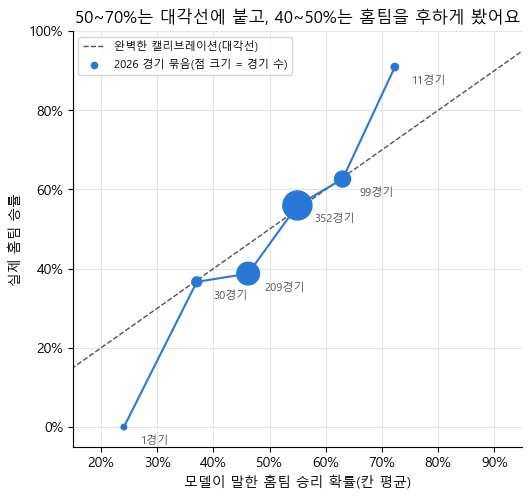

,경기 수,예측 평균,실제 홈팀 승률
칸,,,
20%~30%,1,0.241,0.000
30%~40%,30,0.370,0.367
40%~50%,209,0.462,0.388
50%~60%,352,0.550,0.560
60%~70%,99,0.630,0.626
70%~80%,11,0.723,0.909


In [9]:
bins = pd.DataFrame(report["calibration_bins"])
bins = bins[bins["n"] > 0]
fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.grid(True, axis="both")
ax.plot([0, 1], [0, 1], linestyle="--", color=INK, linewidth=1, label="완벽한 캘리브레이션(대각선)")
ax.plot(bins["pred_mean"], bins["actual_rate"], color=BLUE, linewidth=1.5, zorder=2)
ax.scatter(bins["pred_mean"], bins["actual_rate"], s=bins["n"] * 1.2 + 15, color=BLUE, zorder=3, label="2026 경기 묶음(점 크기 = 경기 수)")
for _, b in bins.iterrows():
    ax.annotate(f"{int(b['n'])}경기", (b["pred_mean"], b["actual_rate"]), xytext=(12, -12), textcoords="offset points", fontsize=8, color=INK)
ax.set(xlim=(0.15, 0.95), ylim=(-0.05, 1.0), xlabel="모델이 말한 홈팀 승리 확률(칸 평균)", ylabel="실제 홈팀 승률",
       title="50~70%는 대각선에 붙고, 40~50%는 홈팀을 후하게 봤어요")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(fontsize=8, loc="upper left", markerscale=0.3)
plt.show()
display(bins.assign(칸=[f"{lo:.0%}~{hi:.0%}" for lo, hi in zip(bins["lo"], bins["hi"])])
            .set_index("칸")[["n", "pred_mean", "actual_rate"]]
            .rename(columns={"n": "경기 수", "pred_mean": "예측 평균", "actual_rate": "실제 홈팀 승률"}).round(3))

**해석:**
- 2026 경기의 **94%**(702경기 중 660경기)가 40~70% 칸에 몰려 있어요. 모델이 "확실하다"고 말하는 경기가 거의 없다는 뜻이고, 야구에서는 정직한 모습이에요.
- 경기가 가장 많은 **50~60% 칸(352경기)**은 예측 55.0% → 실제 56.0%, **60~70% 칸(99경기)**은 63.0% → 62.6%로 대각선과 거의 겹쳐요.
- **40~50% 칸(209경기)**은 예측 46.2%인데 실제 홈팀 승률은 38.8%예요. 이 구간의 홈팀은 모델 생각보다 더 많이 졌어요. 2026 시즌에 "약간 불리한 홈팀"을 조금 후하게 봤다는 뜻이에요.
- 양 끝 칸(1경기, 11경기)은 경기 수가 너무 적어서, 예를 들어 70~80% 칸의 실제 91%(11경기 중 10승)는 우연의 몫이 커요.

## 7. 2026 성적표

드디어 2026 시험 구간을 열어요. `train_report`가 모든 선택을 끝낸 **뒤에** 한 번 채점한 결과를 표로 정리해요.

표의 세 번째 줄 **"선발 뺀 로지스틱 회귀"**는 꼭 함께 봐야 해요.
02번에서 말했듯, 학습과 이 성적표는 박스스코어의 **실제 선발**(투수 순서 1번)로 선발 피처를 만들었어요. 즉 "경기 전에 선발이 누군지 정확히 안다"고 가정한 성적이에요. 라이브 예측은 전날 발표된 **예고 선발**을 쓰니까, 드물게 예고와 다른 투수가 나오면 이 가정이 깨져요.
그래서 선발 피처 7개를 빼고 **팀 피처 19개만으로** 같은 절차(같은 알고리즘·같은 캘리브레이션 방법, OOF로 맞추기)를 다시 돌린 모델을 함께 적어요(`ablation.no_starter`). 선발 정보를 하나도 쓰지 않을 때의 **바닥 성적**이에요.

**출력 보는 법:** 정확도는 높을수록, log loss·Brier는 낮을수록 좋아요. 베이스라인은 확률을 내지 않는 규칙이라 log loss·Brier가 없어요(—).

In [10]:
models, ns = report["models"], report["ablation"]["no_starter"]
rows = []
for k in tw.KINDS:
    m = models[k]
    rows.append({"방법": f"{KIND_NAMES[k]} + {m['calibration']}" + ("  ✔ 선택" if k == selected else ""),
                 "2025 검증 정확도": f"{m['val']['accuracy']:.1%}", "2026 시험 정확도": f"{m['test']['accuracy']:.1%}",
                 "2026 log loss": f"{m['test']['log_loss']:.4f}", "2026 Brier": f"{m['test']['brier']:.4f}"})
rows.append({"방법": f"선발 뺀 {KIND_NAMES[ns['kind']]} (팀 피처 {ns['n_features']}개)",
             "2025 검증 정확도": f"{ns['val']['accuracy']:.1%}", "2026 시험 정확도": f"{ns['test']['accuracy']:.1%}",
             "2026 log loss": f"{ns['test']['log_loss']:.4f}", "2026 Brier": f"{ns['test']['brier']:.4f}"})
for name, label in BASELINE_NAMES.items():
    rows.append({"방법": f"베이스라인: {label}", "2025 검증 정확도": f"{report['baselines']['val'][name]:.1%}",
                 "2026 시험 정확도": f"{report['baselines']['test'][name]:.1%}", "2026 log loss": "—", "2026 Brier": "—"})
scorecard = pd.DataFrame(rows).set_index("방법")
display(scorecard)
print(f"2026 시험 경기 수: {report['n']['test']} · 기준(50%만 말하기): log loss {np.log(2):.4f} · Brier 0.2500")

,2025 검증 정확도,2026 시험 정확도,2026 log loss,2026 Brier
방법,,,,
로지스틱 회귀 + platt ✔ 선택,57.3%,59.4%,0.6712,0.2393
LightGBM + platt,57.9%,59.1%,0.6731,0.2401
선발 뺀 로지스틱 회귀 (팀 피처 19개),54.3%,54.7%,0.6874,0.2471
베이스라인: 무조건 홈팀,51.3%,51.4%,—,—
베이스라인: 승률 높은 팀,54.7%,55.4%,—,—
베이스라인: 선발 ERA 낮은 팀,55.3%,56.7%,—,—


2026 시험 경기 수: 702 · 기준(50%만 말하기): log loss 0.6931 · Brier 0.2500


**해석:**
- 선택된 **로지스틱 회귀 + Platt**은 2026 경기의 **59.4%**를 맞혔어요(702경기 중 417경기). log loss 0.6712, Brier 0.2393으로 세 지표 모두 표에서 가장 좋아요.
- 2025에서 고르지 않은 LightGBM도 2026에서 59.1%로 비슷해요. 2025에서 log loss로 고른 선택이 2026에서도 맞는 방향이었어요.
- 2025 정확도만 보면 LightGBM(57.9%)이 로지스틱 회귀(57.3%)보다 높았어요. 그래도 로지스틱 회귀를 고른 건, 미리 정한 선택 기준이 정확도가 아니라 **log loss**(확률을 얼마나 잘 말했나)이기 때문이에요. 로지스틱 회귀의 2025 정확도가 4번(58.0%)과 다른 건, Platt 보정이 50% 바로 근처 경기 몇 개의 "찍는 쪽"을 바꿨기 때문이에요.
- 2025(57.3%)보다 2026(59.4%)이 더 높은 건 실력이 늘어서가 아니라 시즌마다의 운 차이예요. 702경기짜리 정확도는 ±2%p쯤은 쉽게 흔들려요.
- **선발 뺀 모델은 54.7%**로, 단순 규칙인 "선발 ERA 낮은 팀"(56.7%)은 물론 "승률 높은 팀"(55.4%)보다도 낮아요(무조건 홈팀 51.4%보다는 높아요). 선발 피처가 성적에 **크게 기여**한다는 뜻이에요. 그래서 위 성적표(59.4%)는 "선발을 정확히 안다"는 가정 위의 **위쪽 값**, 54.7%는 선발 정보가 전혀 없을 때의 **바닥 값**으로 읽어 주세요. 예고 선발은 대부분 실제로 등판하니, 라이브 성적은 위쪽 값에 가까울 거라고 기대해요.

### 베이스라인보다 나은 게 우연일까? — McNemar 검정
모델이 "선발 ERA 낮은 팀" 규칙보다 2.7%p 높아요. 그런데 동전을 702번 던져도 앞면 비율이 50%에서 몇 %p쯤은 벗어나듯, 이 정도 차이는 운일 수도 있어요.

**McNemar 검정**(맥니마 검정)은 **같은 경기들**을 두 방법이 함께 풀었을 때를 비교하는 검정이에요. 둘 다 맞힌 경기·둘 다 틀린 경기는 차이를 말해 주지 않으니 빼고, "**한쪽만 맞힌 경기**"만 봐요. 두 방법의 실력이 같다면 한쪽만 맞힌 경기는 반반으로 나뉘어야 하는데, 실제로 얼마나 한쪽으로 쏠렸는지로 **p값**을 계산해요(`tw.mcnemar_p`).
**p값**은 "실력이 같은데도 우연히 이만큼(이상) 차이 날 확률"이에요. 보통 **0.05보다 작으면** "우연으로 보기 어렵다 = **통계적으로 유의하다**"고 말해요.

비교 대상은 3번에서 말한 대로 **2025에서 미리 정한** "선발 ERA 낮은 팀"이에요. 나머지 두 규칙과의 검정도 참고로 함께 적어요.

검정의 재료인 "한쪽만 맞힌 경기" 수도 직접 보여 드릴게요. 성적표에는 맞힌 경기 수만 있어서, 공개 함수(`tw.evaluate`, `tw.baselines`)를 **한 경기씩** 불러 경기별 정답 여부를 얻어요(새 규칙을 짜지 않으려고요). 그걸로 `tw.mcnemar_p`를 다시 돌려 성적표의 p값과 같은지도 확인해요.

**출력 보는 법:** `모델만 맞힘(b)`은 모델은 맞히고 규칙은 틀린 경기, `규칙만 맞힘(c)`은 그 반대예요. 검정은 이 두 칸만 봐요. `차이(%p)`는 (b − c) ÷ 702와 같아요. `◀`가 미리 정한 비교 대상이에요.

In [11]:
sig, n_test = report["significance"], report["n"]["test"]
# 경기별 정답 여부: 공개 함수를 한 경기씩 불러서 얻어요 (정확도 1.0 = 맞힘, 0.0 = 틀림)
one_game = [test.iloc[[i]] for i in range(len(test))]
model_ok = np.array([tw.evaluate(report_bundle, g)["accuracy"] for g in one_game]) == 1
rule_ok = pd.DataFrame([tw.baselines(g) for g in one_game]) == 1
assert model_ok.sum() == sig["model_correct"]
assert all(rule_ok[name].sum() == s["baseline_correct"] for name, s in sig["all"].items())

sig_tbl = pd.DataFrame([{
    "비교 상대": BASELINE_NAMES[name],
    "모델이 맞힌 경기": s["model_correct"],
    "규칙이 맞힌 경기": s["baseline_correct"],
    "모델만 맞힘(b)": int((model_ok & ~rule_ok[name]).sum()),
    "규칙만 맞힘(c)": int((~model_ok & rule_ok[name]).sum()),
    "차이(%p)": round(100 * (s["model_correct"] - s["baseline_correct"]) / n_test, 1),
    "McNemar p": round(s["mcnemar_p"], 4),
    "유의?(p < 0.05)": "예" if s["mcnemar_p"] < 0.05 else "아니요",
    "비교 대상": f"◀ {sig['selected_on']}에서 미리 지정" if name == sig["vs"] else "",
} for name, s in sig["all"].items()]).set_index("비교 상대")
display(sig_tbl)
same_p = all(tw.mcnemar_p(model_ok, rule_ok[name]) == s["mcnemar_p"] for name, s in sig["all"].items())
print("b·c로 다시 계산한 McNemar p가 성적표와 같나요?:", same_p)
assert same_p
gap = 100 * (sig["model_correct"] - sig["baseline_correct"]) / n_test
print(f"미리 정한 비교 대상({BASELINE_NAMES[sig['vs']]}) 대비 +{gap:.1f}%p, McNemar p = {sig['mcnemar_p']:.3f} → "
      + ("통계적으로 유의해요" if sig["mcnemar_p"] < 0.05 else "통계적으로 유의하지 않아요"))

,모델이 맞힌 경기,규칙이 맞힌 경기,모델만 맞힘(b),규칙만 맞힘(c),차이(%p),McNemar p,유의?(p < 0.05),비교 대상
비교 상대,,,,,,,,
무조건 홈팀,417,361,148,92,8.0,0.0004,예,
승률 높은 팀,417,389,132,104,4.0,0.0786,아니요,
선발 ERA 낮은 팀,417,398,115,96,2.7,0.2152,아니요,◀ val에서 미리 지정


b·c로 다시 계산한 McNemar p가 성적표와 같나요?: True
미리 정한 비교 대상(선발 ERA 낮은 팀) 대비 +2.7%p, McNemar p = 0.215 → 통계적으로 유의하지 않아요


**해석 — 좋은 소식과 아직 부족한 점을 그대로 적을게요.**
- **무조건 홈팀** 대비 +8.0%p, p = 0.0004 → 우연으로 보기 어려워요. 모델은 확실히 "아무 생각 없이 찍기"보다 나아요.
- **승률 높은 팀** 대비 +4.0%p, p = 0.079 → 0.05에 가깝지만 넘지 못했어요.
- **선발 ERA 낮은 팀**(미리 정한 비교 대상) 대비 **+2.7%p, p = 0.215** → **통계적으로 유의하지 않아요.** 가장 좋은 단순 규칙보다 2.7%p 높게 나왔지만, 702경기로는 이 차이가 실력인지 운인지 구별할 수 없어요.
- 이 프로젝트의 목표는 "가장 좋은 단순 규칙보다 **+3%p 이상, 그리고 통계적으로 유의**"였어요. 지금은 **+2.7%p, 유의하지 않음**이라서 **목표에는 아직 못 미쳤어요.**

왜 이렇게 어려울까요? 표의 b·c 칸이 답이에요. 모델과 "선발 ERA 낮은 팀" 규칙은 702경기 중 491경기에서 결과가 같았어요(둘 다 맞히거나 둘 다 틀림. 둘 다 선발 정보를 쓰니까요). 승부가 갈린 건 **211경기**뿐이고, 그중 모델이 **115경기(b)**, 규칙이 **96경기(c)**를 가져갔어요. 실력이 같은 두 방법이라도 211번 동전을 던지면 한쪽이 115번 이상(또는 96번 이하) 나올 확률이 약 21.5%예요. 이게 p = 0.215의 뜻이에요. 반대로 무조건 홈팀과는 148 대 92로 크게 갈려서 p = 0.0004가 나왔어요. "유의"하다고 말하려면 차이가 더 커지거나, 더 많은 시즌의 경기로 확인해야 해요.
다음 단계(3단계, 노트북 04)에서 선수 유형과 유형 상성 피처를 더한 전후를 비교하면서 이 목표를 다시 확인해요. 성적표의 `matchup_feature_ablation`, `cluster_quality` 칸이 지금 비어 있는(`null`) 이유예요.

## 8. 피처 중요도와 한 경기 요인 분해

### 8-1. 어떤 피처가 중요했나?
**피처 중요도**는 모델이 어떤 피처에 많이 기댔는지를 합이 1(100%)이 되게 나눈 몫이에요(`tw.feature_importance`).
- **로지스틱 회귀**(왼쪽, 선택된 모델 — 성적표에 실린 값): 4번의 **표준화 계수의 절댓값** 비율이에요.
- **LightGBM**(오른쪽, 비교용): 나무가 그 피처로 경기를 나눌 때마다 log loss가 줄어든 양(**gain**, 이득)의 합이에요.

두 모델은 중요도를 재는 방식이 달라서 숫자를 직접 비교할 수는 없지만, **순위가 비슷한지**는 볼 수 있어요.

**출력 보는 법:** 파란 막대는 선발투수 피처 7개, 회색 막대는 팀 피처 19개예요. 아래 줄은 선발 피처 7개의 몫을 합친 값이에요.

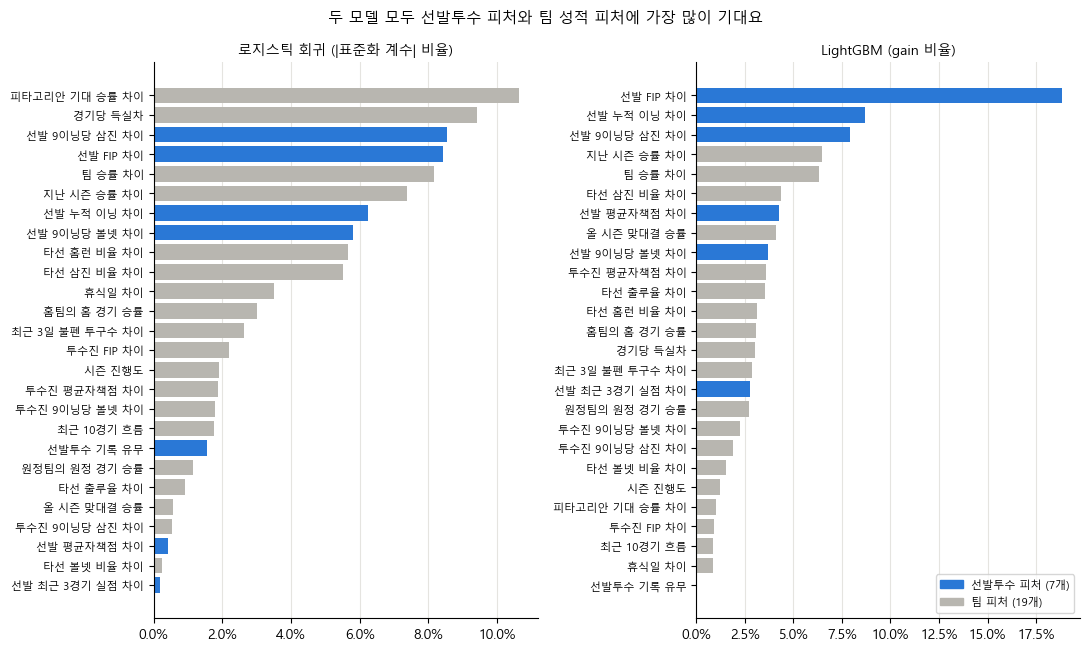

로지스틱 회귀: 선발 피처 7개의 몫 31.1% · 1위 피타고리안 기대 승률 차이 (10.6%)
LightGBM: 선발 피처 7개의 몫 46.2% · 1위 선발 FIP 차이 (18.8%)


In [12]:
imp_lr = pd.DataFrame(report["feature_importance"])            # 선택된 모델(로지스틱 회귀)의 중요도, 성적표에 실린 그대로
imp_lgbm = pd.DataFrame(tw.feature_importance(lgbm_raw))       # 5번의 52그루 LightGBM
starter = set(features.STARTER_FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(11, 6.6))
for ax, imp, title in ((axes[0], imp_lr, "로지스틱 회귀 (|표준화 계수| 비율)"), (axes[1], imp_lgbm, "LightGBM (gain 비율)")):
    imp = imp.iloc[::-1]   # 큰 값이 위로 오게
    ax.barh(imp["label"], imp["importance"], color=[BLUE if n in starter else GRAY for n in imp["name"]])
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(True, axis="x")
    ax.grid(False, axis="y")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].legend(handles=[Patch(color=BLUE, label="선발투수 피처 (7개)"), Patch(color=GRAY, label="팀 피처 (19개)")],
               loc="lower right", fontsize=8)
fig.suptitle("두 모델 모두 선발투수 피처와 팀 성적 피처에 가장 많이 기대요", fontsize=11)
fig.tight_layout()
plt.show()
for name, imp in (("로지스틱 회귀", imp_lr), ("LightGBM", imp_lgbm)):
    share = imp.loc[imp["name"].isin(starter), "importance"].sum()
    print(f"{name}: 선발 피처 7개의 몫 {share:.1%} · 1위 {imp['label'].iloc[0]} ({imp['importance'].iloc[0]:.1%})")

**해석:**
- 로지스틱 회귀는 1~2위가 **피타고리안 승률·득실차**(4번에서 본 "서로 몫을 나눈" 한 쌍)이고, 그다음이 선발 K/9·선발 FIP·팀 승률이에요.
- LightGBM은 **선발 FIP 차이** 하나가 19%로 압도적 1위예요. 나무 모델은 비슷한 피처 중 하나를 골라 집중적으로 쓰는 경향이 있어서, 선발 실력을 FIP 하나로 몰아서 본 거예요.
- 선발 피처 7개는 피처 수로는 27%인데, 중요도로는 로지스틱 회귀 31%, LightGBM 46%를 차지해요. 7번에서 선발을 빼면 성적이 크게 떨어진 것과 같은 이야기예요.
- 휴식일·불펜 투구수·맞대결 승률 같은 피처는 두 모델 모두에서 작은 몫이에요. 02번에서 "약한 신호"라고 봤던 그대로예요.

### 8-2. 한 경기의 예측을 요인으로 나누기
사이트는 경기마다 "왜 이 확률이 나왔는지" **요인 상위 5개**를 보여 줘요. 그 계산을 한 경기로 따라가 볼게요.

**요인 분해**는 한 경기의 예측 점수(로짓)를 **"평균적인 경기의 점수(기본값) + 피처마다의 기여"**로 정확히 나누는 거예요(`tw.explain`).
- **로지스틱 회귀**: 기여 = 계수 × 그 경기의 표준화 값. 점수가 원래 덧셈이라 그대로 나뉘어요. 기본값은 절편인데, **대략** "평균적인 경기의 홈 어드밴티지"로 읽을 수 있어요. '대략'인 이유는 피처 26개 중 4개(`home_venue_pct`, `away_venue_pct`, `season_progress`, `starter_known`)가 홈 − 원정 차이가 아니라서, 절편에 이 피처들의 평균 수준 몫도 섞여 있기 때문이에요.
- **LightGBM**: 나무 모델은 덧셈이 아니라서 **SHAP**(SHapley Additive exPlanations: 게임 이론의 "공정한 몫 나누기"로 각 피처의 기여를 계산하는 방법)을 써요. LightGBM에는 나무 구조를 이용해 SHAP을 빠르고 정확하게 계산하는 **TreeSHAP**이 들어 있어요(`pred_contrib=True`).

두 방법 모두 **기여의 합 + 기본값 = 그 경기의 로짓**이 정확히 성립해요.
사이트에는 로짓 대신 이해하기 쉬운 **%p(퍼센트포인트)**로 보여 줘요(`predict.factor_pp`). 로짓 1만큼의 변화는 확률 p 근처에서 약 p(1−p)만큼의 확률 변화라서, **pp = 기여 × Platt 기울기 a × p(1−p) × 100**으로 바꿔요. 이건 **1차 근사**(곡선을 그 점의 접선으로 바꿔 계산)라서, pp를 모두 더해도 "확률 − 50%"와 정확히 같지는 않아요.

예시 경기는 **2026-08-18 롯데(홈) vs 키움(원정)**(game_id 13836)이에요. 모델이 홈팀에 74%를 준, 2026에서 가장 자신 있던 경기 중 하나예요.

**출력 보는 법:** 사이트와 같은 규칙(|pp|가 큰 순서)으로 8개를 그려요. 파란 막대는 홈팀 쪽으로, 주황 막대는 원정팀 쪽으로 확률을 민 요인이에요. 아래 줄에서 원정 쪽 요인, 선발 피처 값, 항등식과 1차 근사를 확인해요.

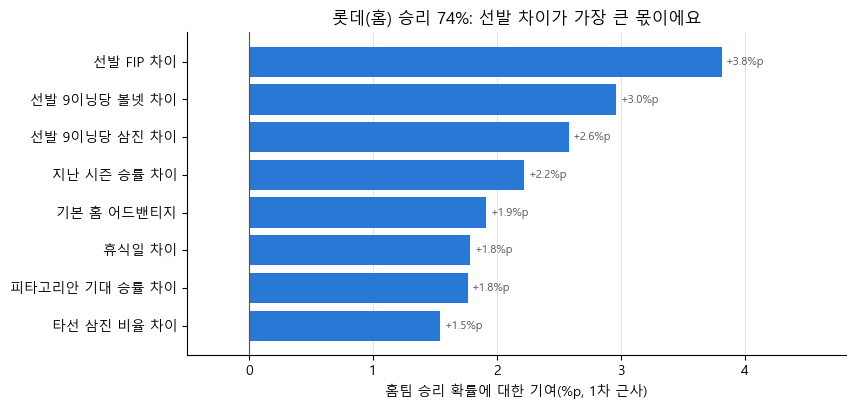

2026-08-18 LT(홈) vs WO(원정) · 모델 확률 74.0% · 실제 결과: 홈 승
항등식: 기여 합 + 기본값 = 1.235847, 캘리브레이션 전 로짓 = 1.235847 → 같나요?: True
원정 쪽으로 가장 크게 민 요인: 경기당 득실차 (-1.5%p)
선발 피처(홈 − 원정): {'starter_fip_diff': -3.22, 'starter_bb9_diff': -5.71, 'starter_k9_diff': 3.0}
1차 근사: 요인 27개 pp 합 +19.8%p vs 실제 확률 − 50% = +24.0%p


In [13]:
GAME_ID = 13836   # 2026-08-18 롯데(LT, 홈) vs 키움(WO, 원정)
game = test[test["game_id"] == GAME_ID]
p_game = float(tw.predict_proba(report_bundle, game)[0])                   # 최종 확률(캘리브레이션 후)
contrib, base = tw.explain(report_bundle, game)                           # 로짓 단위 기여 26개 + 기본값
raw_logit = np.log(tw.predict_raw(report_bundle, game)[0] / (1 - tw.predict_raw(report_bundle, game)[0]))

pp = pd.DataFrame(predict.factor_pp(report_bundle, game, p_game), columns=["요인", "pp"])
top = pp.reindex(pp["pp"].abs().sort_values(ascending=False).index).head(8).iloc[::-1]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
bars = ax.barh(top["요인"], top["pp"], color=[BLUE if v > 0 else ORANGE for v in top["pp"]])
ax.bar_label(bars, labels=[f"{v:+.1f}%p" for v in top["pp"]], fontsize=8, color=INK, padding=3)
ax.axvline(0, color=INK, linewidth=0.8)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.set(xlim=(min(0, top["pp"].min()) - 0.5, top["pp"].max() + 1), xlabel="홈팀 승리 확률에 대한 기여(%p, 1차 근사)",
       title=f"롯데(홈) 승리 {p_game:.0%}: 선발 차이가 가장 큰 몫이에요")
plt.show()

row = game.iloc[0]
print(f"{row['date']} {row['home_code']}(홈) vs {row['away_code']}(원정) · 모델 확률 {p_game:.1%} · 실제 결과: {'홈 승' if row['y'] == 1 else '원정 승'}")
print(f"항등식: 기여 합 + 기본값 = {contrib.sum() + base[0]:.6f}, 캘리브레이션 전 로짓 = {raw_logit:.6f} → 같나요?:",
      bool(np.isclose(contrib.sum() + base[0], raw_logit)))
away_side = pp.loc[pp["pp"].idxmin()]
print(f"원정 쪽으로 가장 크게 민 요인: {away_side['요인']} ({away_side['pp']:+.1f}%p)")
print("선발 피처(홈 − 원정):", {n: round(float(row[n]), 2) for n in ("starter_fip_diff", "starter_bb9_diff", "starter_k9_diff")})
print(f"1차 근사: 요인 27개 pp 합 {pp['pp'].sum():+.1f}%p vs 실제 확률 − 50% = {100 * (p_game - 0.5):+.1f}%p")

**해석:**
- 롯데에 74%를 준 가장 큰 이유는 **선발투수**예요. 선발 FIP(+3.8%p)·선발 BB/9(+3.0%p)·선발 K/9(+2.6%p) 세 요인만 더해도 +9%p가 넘어요. 이 경기는 롯데 선발이 키움 선발보다 FIP가 3.2 낮고, 9이닝당 볼넷이 5.7개 적었어요.
- 그다음은 **지난 시즌 승률 차이**(+2.2%p)와 **기본 홈 어드밴티지**(+1.9%p, 모든 경기에 똑같이 붙는 기본값)예요.
- 이 경기에서는 상위 8개가 모두 홈팀 쪽(파랑)이에요. 원정 쪽으로 가장 크게 민 요인은 **경기당 득실차**(−1.5%p)로 아깝게 9위예요. 4번에서 본 것처럼 득실차는 피타고리안 승률(+1.8%p)과 몫을 나눠 가지는 짝이라, 둘을 합치면 +0.3%p로 거의 상쇄돼요. 요인도 계수처럼 **묶음으로** 읽는 게 안전해요.
- 요인 pp를 모두 더하면 +19.8%p인데 실제 확률은 50%보다 +24.0%p예요. 1차 근사라서 생기는 차이로, 사이트는 이 pp를 "어느 요인이 얼마나 크게 작용했나"의 **순위와 크기 감**으로 보여 줘요. 실제로 이 경기는 롯데가 이겼어요.

### 같은 경기를 LightGBM(TreeSHAP)은 어떻게 나눴을까?
선택된 모델은 로지스틱 회귀지만, LightGBM의 TreeSHAP도 같은 경기에서 비슷한 이야기를 하는지 보면 요인 분해를 더 믿을 수 있어요.

**출력 보는 법:** 단위는 둘 다 **로짓**(캘리브레이션 전)이에요. 로지스틱 회귀 기여의 절댓값이 큰 8개 요인을 두 모델 나란히 놓았어요. 마지막 줄은 LightGBM에서도 항등식이 성립하는지 확인해요.

In [14]:
shap_contrib, shap_base = tw.explain(lgbm_raw, game)                      # LightGBM 내장 TreeSHAP
labels = [features.FACTOR_LABELS[n] for n in features.FEATURE_NAMES] + [features.FACTOR_LABELS["bias"]]
side = pd.DataFrame({"로지스틱 회귀 기여(로짓)": np.append(contrib[0], base[0]),
                     "LightGBM TreeSHAP 기여(로짓)": np.append(shap_contrib[0], shap_base[0])}, index=labels)
display(side.reindex(side.iloc[:, 0].abs().sort_values(ascending=False).index).head(8).round(3))
p_lgbm_raw = tw.predict_raw(lgbm_raw, game)[0]
print(f"LightGBM 항등식: SHAP 합 + 기본값 = {shap_contrib.sum() + shap_base[0]:.6f}, 로짓 = {np.log(p_lgbm_raw / (1 - p_lgbm_raw)):.6f}"
      f" → 같나요?: {bool(np.isclose(shap_contrib.sum() + shap_base[0], np.log(p_lgbm_raw / (1 - p_lgbm_raw))))}"
      f" · LightGBM 확률(캘리브레이션 전) {p_lgbm_raw:.1%}")

,로지스틱 회귀 기여(로짓),LightGBM TreeSHAP 기여(로짓)
선발 FIP 차이,0.238,0.242
선발 9이닝당 볼넷 차이,0.185,0.034
선발 9이닝당 삼진 차이,0.161,0.072
지난 시즌 승률 차이,0.138,0.062
기본 홈 어드밴티지,0.119,0.118
휴식일 차이,0.111,0.026
피타고리안 기대 승률 차이,0.110,0.000
타선 삼진 비율 차이,0.096,0.049


LightGBM 항등식: SHAP 합 + 기본값 = 0.733167, 로짓 = 0.733167 → 같나요?: True · LightGBM 확률(캘리브레이션 전) 67.5%


**해석:** LightGBM에서 거의 0인 피타고리안 승률을 빼면, 나머지 7개 요인 모두 두 모델에서 **같은 방향**(홈팀 쪽)이고, 가장 큰 기여가 **선발 FIP 차이**(둘 다 약 0.24)라는 점도 같아요. 기본 홈 어드밴티지도 0.119 vs 0.118로 거의 같아요.
다른 점은, LightGBM이 8-1에서 본 것처럼 선발 실력을 **FIP 하나에 몰아서** 보기 때문에 BB/9·K/9에는 훨씬 작은 몫을 주고, 피타고리안 승률은 거의 쓰지 않는다는 거예요. 그래서 LightGBM의 확률(캘리브레이션 전 67.5%)은 로지스틱 회귀보다 덜 자신 있어요.
두 모델이 계산 방식은 전혀 다르지만 "이 경기는 선발 차이 때문에 홈팀이 유리하다"는 결론은 같아요. 사이트에 보여 주는 요인은 선택된 로지스틱 회귀의 값이에요.

## 9. 라이브 모델 — 매일 예측에 쓰는 v0.2

성적표 모델은 2025·2026을 학습에 쓰지 않았어요. 하지만 매일 예측할 때는 **최근 시즌일수록 중요한 정보**라서, 가지고 있는 모든 시즌(2015~2026)으로 다시 학습해요(`tw.train_live`).
이때 알고리즘·캘리브레이션 방법·나무 수는 **성적표가 고른 값을 그대로** 써요(새로 고르면 그 선택은 채점된 적이 없으니까요).
전체를 학습에 쓰면 캘리브레이터를 맞출 "안 본 데이터"가 남지 않으므로, 6번과 똑같이 **시즌 leave-one-out OOF 예측**(이번에는 12개 시즌)으로 Platt을 맞춰요.

명령줄에서는 `python -m kbo_predict.train_win live`가 같은 일을 해서 `models/win_model.pkl`을 만들어요. 노트북에서 방금 학습한 모델과 저장소의 파일을 비교해 볼게요(`meta`에는 실행 시각을 넣지 않아요. 학습 시각 칸만 달라지고 모델에는 영향이 없어요).

**출력 보는 법:** 표의 두 열이 같고, 아래 줄이 `True`면 8,465경기 전부에서 두 모델의 확률이 **소수점 끝자리까지** 같다는 뜻이에요.

In [15]:
t = time.time()
live = tw.train_live(df, kind=selected, calibration=report["models"][selected]["calibration"],
                     n_estimators=report["models"]["lgbm"]["best_iteration"], meta={})
print(f"train_live 실행 시간: {time.time() - t:.1f}초")
saved_live = tw.load_bundle(ROOT / "models" / "win_model.pkl")

summary = pd.DataFrame({name: {
    "버전": b["version"], "알고리즘": b["kind"], "캘리브레이션": b["calibration"],
    "학습 시즌": f"{b['seasons'][0]}~{b['seasons'][-1]}", "학습 경기 수": f"{b['n_games']:,}", "피처 수": len(b["features"]),
    "Platt 기울기 a": f"{b['calibrator'].coef_[0][0]:.4f}", "Platt 절편 b": f"{b['calibrator'].intercept_[0]:+.4f}",
} for name, b in (("노트북에서 방금 학습", live), ("models/win_model.pkl", saved_live))})
display(summary)
same_live = bool(np.array_equal(tw.predict_proba(live, df), tw.predict_proba(saved_live, df)))
print(f"전체 {len(df):,}경기의 예측 확률이 저장된 라이브 모델과 똑같나요?: {same_live}")
assert same_live

train_live 실행 시간: 0.6초


,노트북에서 방금 학습,models/win_model.pkl
버전,v0.2,v0.2
알고리즘,lr,lr
캘리브레이션,platt,platt
학습 시즌,2015~2026,2015~2026
학습 경기 수,"8,465","8,465"
피처 수,26,26
Platt 기울기 a,0.8777,0.8777
Platt 절편 b,+0.0104,+0.0104


전체 8,465경기의 예측 확률이 저장된 라이브 모델과 똑같나요?: True


**해석:** 라이브 모델 v0.2는 **로지스틱 회귀 + Platt**, 2015~2026 **8,465경기**로 학습했어요. 노트북에서 만든 모델과 저장소의 `win_model.pkl`이 모든 경기에서 같은 확률을 내요.
Platt 기울기는 0.878로 성적표 모델(0.834)과 비슷해요. 데이터가 늘어도 "원래 확률을 조금 50% 쪽으로 당긴다"는 보정의 성격은 그대로예요.
라이브 모델은 2026까지 배웠기 때문에 2026으로 채점하지 않아요. 그 대신 **같은 방법으로 만든 성적표 모델의 2026 점수(59.4%)**가 이 모델의 실력을 대신 보여 줘요.

## 10. 유형 상성 피처를 넣으면?

04번 노트북에서 타자·투수를 기록으로 묶어 **선수 유형**(타자 4가지, 투수 4가지)을 만들었어요. 여기서는 그 유형을 승패 예측의 재료로 써 봐요.

### 어떤 피처인가요?
경기마다 **직전 시즌 유형**을 기준으로 아래 9개 피처를 만들어요(모두 홈 − 원정).
- `bat_type0_diff` ~ `bat_type3_diff` (4개): 그날 **타선 9명** 중 각 유형 타자의 수 차이
- `starter_type0_diff` ~ `starter_type3_diff` (4개): **상대 선발 투수의 유형**(그 유형이면 1, 아니면 0)의 홈 − 원정 차이
- `types_known` (1개): 이 경기에서 유형 정보를 쓸 수 있었는지(1이면 있음)

직전 시즌 유형을 쓰는 건 그 경기가 속한 시즌의 성적을 미리 엿보지 않기 위해서예요. 대신 직전 시즌에 자격(200타석·50이닝·구원 30경기)을 못 채운 선수는 유형이 없어요.

### 어떻게 비교하나요?
6번에서 **고른 알고리즘·캘리브레이션·나무 수는 그대로** 두고 피처만 26개 → 35개로 늘려서 학습·채점해요(`tw.train_report`의 `matchup_feature_ablation`). 이렇게 **하나만 바꿔서 전후를 비교하는 것**을 ablation이라고 해요. 같은 경기들(검증 698경기, 시험 702경기)로 전·후를 재고, 시험 경기에서 둘의 예측이 갈린 정도가 우연인지 McNemar 검정으로 확인해요.

**출력 보는 법:** 표의 행은 구간(검증 2025·시험 2026)과 피처 구성(전·후)이에요. 정확도는 높을수록, log loss·Brier는 낮을수록 좋아요. 아래에 McNemar p값, 채택 여부(`adopt`), 검증 범위 주의가 나와요.

In [16]:
mf = report["matchup_feature_ablation"]
rows = []
for part, label in (("val", "검증 2025"), ("test", "시험 2026")):
    for key, name in (("without", "상성 없음 (26개)"), ("with", "상성 있음 (35개)")):
        m = mf[key][part]
        rows.append({"구간": label, "피처": name, "경기 수": m["n"], "정확도": f"{m['accuracy']:.1%}",
                     "log loss": f"{m['log_loss']:.4f}", "Brier": f"{m['brier']:.4f}"})
display(pd.DataFrame(rows).set_index(["구간", "피처"]))
print(f"추가된 피처 {len(mf['features_added'])}개 · 군집 버전 {mf['cluster_version']} · 군집 맞춤 시즌 {mf['fit_seasons'][0]}~{mf['fit_seasons'][-1]}")
print(f"McNemar p (시험, 전 vs 후): {mf['mcnemar_p_test']:.3f}")
print(f"adopt (채택 여부): {mf['adopt']}")
print("검증 범위:", mf["validation_scope"])
print(f"유형 정보가 있는 경기(types_known = 1) 비율: 전체 {games['types_known'].mean():.1%} · 2026 {games.loc[games['season'] == 2026, 'types_known'].mean():.1%}")

경기 수    정확도 log loss   Brier
구간      피처                                       
검증 2025 상성 없음 (26개)   698  57.3%   0.6771  0.2421
        상성 있음 (35개)   698  56.9%   0.6778  0.2424
시험 2026 상성 없음 (26개)   702  59.4%   0.6712  0.2393
        상성 있음 (35개)   702  59.1%   0.6713  0.2393

추가된 피처 9개 · 군집 버전 clusters-2026 · 군집 맞춤 시즌 2015~2025
McNemar p (시험, 전 vs 후): 0.845
adopt (채택 여부): False
검증 범위: 검증(2025) 비교의 직전 시즌(2024) 유형은 2025 성적까지 본 2015~2025 맞춤 중심으로 매겨져 엄밀한 시간 외(out-of-time) 비교가 아닌 전이적(transductive) 비교이고, test(2026) 비교만 엄밀한 시간 외 비교다.
유형 정보가 있는 경기(types_known = 1) 비율: 전체 26.9% · 2026 15.5%


**해석:** 상성 피처를 더해도 **나아지지 않았어요.** 검증 정확도는 57.3% → 56.9%, 시험 정확도는 59.4% → 59.1%로 조금 낮아지고, log loss·Brier는 소수점 셋~넷째 자리에서 거의 같아요. McNemar p = **0.845**라서 두 모델의 차이는 우연 수준이에요. 그래서 `adopt`는 **false** — 채택하지 않았어요.

**그래서 라이브 모델은 그대로예요.** 9번의 라이브 모델 v0.2는 기존 피처 26개만 쓰고, 사이트의 예측도 바뀌지 않아요. 상성 피처를 라이브에 연결하는 일은 채택 기준을 통과했을 때의 일인데, 이번에는 통과하지 못했어요(라이브 반영은 4단계에서 해요).

**왜 도움이 안 됐을까요?** 가장 큰 이유는 **커버리지**예요. 유형 정보가 채워진 경기는 전체의 약 27%뿐이고, 채점에 쓰는 **2026은 15.5%**예요(신인·첫해 외국인 선수·부상 복귀 선수는 직전 시즌 유형이 없어요). 대부분의 경기에서 새 피처는 `0`이라 모델이 배울 게 적어요. 게다가 02번의 피처가 이미 장타력·삼진·선발의 삼진/볼넷을 숫자 그대로 담고 있어서, 유형이 더할 정보가 많지 않은 것으로 보여요. 자세한 커버리지 분석은 04번에 있어요.

**검증 범위 주의:** 유형의 중심은 2015~2025 성적으로 맞췄기 때문에 2025 검증 비교는 엄밀한 "미래를 모르는" 비교가 아니라 **전이적 비교**예요. **2026 시험만** 엄밀한 시간 외 비교인데, 거기서도 나아지지 않았어요.

## 11. 동일성 확인 — 노트북 결과 = 저장소의 성적표

마지막으로, 6번에서 이 노트북이 `train_report`로 만든 성적표(dict)가 저장소에 공개된 `data/public/model_report.json`과 **완전히 같은지** 비교해요.
- 실행 시각 `generated_at`만 양쪽에서 빼요(실행할 때마다 다르니까요). 나머지는 모델 버전, 시즌 구성, 모든 지표, 캘리브레이션 표, 피처 중요도, 유의성 검정, 선발 뺀 변형까지 **한 칸도 빠짐없이** 비교해요.
- 함께 `models/report-2026.pkl`(얼려 둔 성적표 모델)이 8,465경기 전부에서 노트북 모델과 같은 확률을 내는지도 봐요.

같다면 "이 노트북으로 설명한 과정 = 명령줄(`python -m kbo_predict.train_win report`)이 실제로 돌린 과정"이라는 증거예요. 다음 단계(4단계)에서는 이 비교를 자동 테스트로 만들어서, 코드나 데이터가 바뀌면 바로 알아챌 수 있게 할 거예요.

**출력 보는 법:** ✅ 줄이 나오면 같아요. 다르면 ❌와 함께 다른 항목 이름이 나오고 셀이 오류로 멈춰요. 맨 아래 줄은 노트북 전체 실행 시간이에요.

In [17]:
mine = {k: v for k, v in report.items() if k != "generated_at"}
theirs = {k: v for k, v in committed.items() if k != "generated_at"}
different = sorted(k for k in mine.keys() | theirs.keys() if mine.get(k) != theirs.get(k))
saved_report = tw.load_bundle(ROOT / "models" / "report-2026.pkl")
same_bundle = bool(np.array_equal(tw.predict_proba(report_bundle, df), tw.predict_proba(saved_report, df)))

print(f"비교한 항목: {len(mine)}개 (generated_at 제외) — 다른 항목: {different or '없음'}")
print(f"models/report-2026.pkl과 예측 확률이 같나요?: {same_bundle}")
if mine == theirs and same_bundle:
    print("✅ 같아요! 노트북이 만든 성적표 = data/public/model_report.json")
else:
    print("❌ 달라요! features.parquet나 train_win.py가 성적표를 만든 뒤에 바뀌었어요")
assert mine == theirs and same_bundle
print(f"노트북 전체 실행 시간: {time.time() - T0:.1f}초")

비교한 항목: 18개 (generated_at 제외) — 다른 항목: 없음
models/report-2026.pkl과 예측 확률이 같나요?: True
✅ 같아요! 노트북이 만든 성적표 = data/public/model_report.json
노트북 전체 실행 시간: 13.1초


## 12. 요약과 다음 이야기

### 오늘 확인한 것
- 시즌을 **학습 2015~2024 / 검증 2025 / 시험 2026**으로 시간 순서대로 나눴어요. 나무 수·캘리브레이션·알고리즘·비교 대상은 모두 2025에서 고르고, 2026은 어떤 학습·선택에도 쓰지 않았어요(홀드아웃). 다만 개발 중에 2026 지표를 확인했고 캘리브레이션 선택 절차를 한 번 바꿨어요(R7) — 예전 절차의 결과는 LightGBM + isotonic, 정확도 .588 / log loss .679(p = .321)였어요(2번).
- 성적표용 모델(`report-2026`, 얼려 둠)과 라이브 모델(`v0.2`, 2015~2026 전체 학습)을 따로 둬서, 공개 점수가 부풀지 않게 했어요.
- **로지스틱 회귀**가 LightGBM보다 2025 log loss가 낮아 선택됐어요. LightGBM은 early stopping으로 52그루에서 멈췄어요.
- 캘리브레이터는 학습 구간의 **시즌 leave-one-out OOF 예측**으로 맞추고 2025로 방법만 골랐어요. **Platt**이 뽑혔고, 2026 신뢰도 곡선에서 50~70% 구간(451경기)은 대각선과 잘 맞았어요. 하지만 **40~50% 구간**(209경기, 시험 경기의 약 30%)은 예측 46.2%인데 실제 홈팀 승률이 38.8%로, "약간 불리한 홈팀"을 후하게 봤어요. 다음 단계에서 계속 지켜볼 약점이에요.
- **2026 성적표:** 정확도 **59.4%**, log loss 0.6712, Brier 0.2393. 무조건 홈팀(51.4%)보다 확실히 낫고(p < 0.001), 가장 좋은 단순 규칙(선발 ERA 낮은 팀, 56.7%)보다 **+2.7%p** 높지만 **통계적으로 유의하지는 않아요**(p = 0.215). "+3%p 이상, 유의"라는 목표는 아직 못 이뤘어요.
- 이 성적은 "선발을 정확히 안다"는 가정 위의 값이에요. 선발 피처를 빼면 **54.7%**로 승률·선발 ERA 규칙보다 약해져서(무조건 홈팀 51.4%보다는 높아요), 선발 피처가 성적에 크게 기여한다는 걸 확인했어요.
- 한 경기의 확률을 요인으로 나누는 방법(로지스틱 회귀의 선형 분해, LightGBM의 TreeSHAP)과, 사이트에 보여 주는 %p가 1차 근사라는 점을 봤어요.
- 노트북이 만든 성적표가 저장소의 `model_report.json`과 **한 칸도 다르지 않고**, 두 모델 파일도 노트북 모델과 같은 확률을 낸다는 걸 확인했어요.

### 다음 이야기
- **04. 선수 유형 클러스터링:** 이미 만들어져 있어요. 타자·투수를 기록으로 묶어 선수 유형을 만들고, 유형 상성 피처의 전후 비교(이 노트북 10번)를 04번에서 더 자세히 풀어 놓았어요.
- **4단계:** 이 노트북 11번의 동일성 확인을 자동 검사(`check_parity.py`)로 만들어, 코드나 데이터가 바뀌면 GitHub Actions가 바로 알아채게 해요.
- **5단계:** 이 성적표를 웹사이트의 "모델 성적표" 화면으로 보여 줘요.
- **05. 오늘 경기 예측 (4단계):** 라이브 모델로 오늘 경기를 예측하는 노트북이 다음 차례예요.